# Calibration templates for virgil

The [pair test](pair_test.md) measures the errors that consecutive frames don't share. Errors that come from the calibration itself (transfer-function jitter, injection losses, coherence loss) are better measured on **calibrators**. Calibrated against each other, calibrators should give V² = 1 (or their known diameter's V²), so their residuals *are* the calibration errors.

The **calibrator PCA** finds the spectral shapes those residuals share, how large they are, and how much of each is telescope-based. A **template** packages them as nuisance modes per (frame, telescope) and per (frame, baseline), which virgil marginalises with `OIData.with_gains(modes=...)`.

This tutorial runs the whole chain on simulated data with a known systematic:

1. find it with the calibrator PCA;
2. build a template from it;
3. calibrate science exposures with the template, and fit each one in virgil with and without the modes, to see whose error bars are right.

In [1]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from virgil.plotting import set_style

from virgil_vlti import read_exposure
from virgil_vlti.calpca import (
    calibrator_residuals,
    cross_validate,
    heldout_widths,
    telescope_fraction,
    weighted_pca,
)
from virgil_vlti.cli import main as calibrate
from virgil_vlti.synthetic import add_systematics, write_product
from virgil_vlti.templates import build_template

set_style()
rng = np.random.default_rng(0)
work = Path(tempfile.mkdtemp())
raw = work / "reduced"
raw.mkdir()
INS = "GRAVITY_SC"

## Data with a calibration systematic

Eight nights, each with four point-source calibrators and, between them, three exposures of a science target, a Gaussian disk 2.5 mas across. On top of 0.4% noise, every frame's V² carries a gain per telescope, ~N(0, 3%) on log V², with a spectral shape that is partly grey and partly chromatic (like a coherence loss, larger in the blue). The pipeline records each calibrator's diameter in its header (`ESO QC TF CAL_SC DIAM`), which the PCA needs.

In [2]:
WAVE = np.linspace(2.0e-6, 2.4e-6, 40)
SHAPE = 1 + 2 * ((2.2e-6 / WAVE) ** 2 - 1)  # the systematic's spectral shape
WIDTH = 0.03  # its rms per telescope, on log V²
FWHM, MAS = 2.5, np.pi / 180 / 3600 / 1000


def disk_v2(u, v, wave):
    rho = np.hypot(u, v) / wave
    return np.exp(-((np.pi * FWHM * MAS * rho) ** 2) / (2 * np.log(2)))


calibrators = []
for night in range(8):
    for k in range(4):
        path = write_product(
            raw / f"night{night}_cal{k}.fits",
            mjd=60400.1 + night + k * 0.03,
            wave=WAVE,
            vis2=lambda u, v, w, t: np.full_like(w, 0.8),
            t3phi=lambda *args: np.zeros_like(args[4]),
            catg="SINGLE_CAL_VIS",
            target=f"STAR{night}_{k}",
            vis2err=0.0032,
            t3phierr=0.5,
            header={"ESO QC TF CAL_SC DIAM": 0.0, "ESO QC TF CAL_SC DIAM ERR": 0.01},
        )
        add_systematics(path, INS, rng=rng, white=1.0, telescope=WIDTH, shape=SHAPE, cp_white=1.0)
        calibrators.append(read_exposure(str(path)))
    for j in range(3):  # science, between the calibrators
        path = write_product(
            raw / f"night{night}_sci{j}.fits",
            mjd=60400.1 + night + 0.015 + j * 0.03,
            wave=WAVE,
            vis2=lambda u, v, w, t: 0.8 * disk_v2(u, v, w),
            t3phi=lambda *args: np.zeros_like(args[4]),
            catg="SINGLE_SCI_VIS",
            target="TARGET",
            vis2err=0.0032,
            t3phierr=0.5,
        )
        add_systematics(path, INS, rng=rng, white=1.0, telescope=WIDTH, shape=SHAPE, cp_white=1.0)

## 1. The calibrator PCA

`calibrator_residuals` calibrates every calibrator by the others of its night, leaving it out, and returns the residuals of log V² and of closure phase, one row per (frame, baseline) or (frame, triangle). `cross_validate` then asks how many principal components are real: components fitted on some nights must lower χ² on the held-out nights by more than fitting noise would (the last column). On archival data, `virgil-vlti-calpca` does all this from the command line.

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    residuals = calibrator_residuals(calibrators, INS)
v2 = residuals["vis2"]
print(f"{v2.r.shape[0]} residual spectra of {v2.r.shape[1]} channels")

print("k   held-out χ²/sample   expected for noise")
for k, chi2, noise in cross_validate(v2, 3, folds=4):
    print(f"{k}   {chi2:18.3f}   {noise:18.3f}")

576 residual spectra of 40 channels
k   held-out χ²/sample   expected for noise


0              130.699                1.000
1                0.987                0.975
2                0.964                0.950
3                0.939                0.925


The first component lowers the held-out χ² far below what fitting noise would; later ones gain no more than noise. Its shape is the one we injected, and its telescope fraction says it is telescope-based (with no telescope structure the fraction would be 4/6):

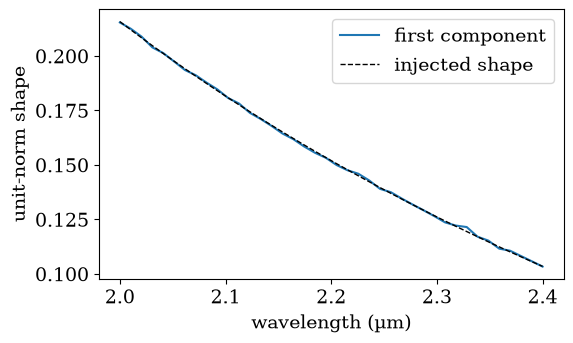

held-out width 0.322 (log V², per baseline); telescope fraction 1.00


In [4]:
pca = weighted_pca(v2, 1)
component = pca.components[0]
shape = SHAPE / np.linalg.norm(SHAPE)
component = component * np.sign(component @ shape)
width = heldout_widths(v2, 1, folds=4)[0]
fraction = telescope_fraction(v2, pca.amplitudes)[0]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(WAVE * 1e6, component, label="first component")
ax.plot(WAVE * 1e6, shape, "k--", lw=1, label="injected shape")
ax.set(xlabel="wavelength (µm)", ylabel="unit-norm shape")
ax.legend()
plt.show()
print(f"held-out width {width:.3f} (log V², per baseline); telescope fraction {fraction:.2f}")

## 2. A template

`build_template` turns each V² component into a **telescope gain** per (frame, telescope) and a **baseline gain** per (frame, baseline), split by the telescope fraction, as modes on log |V| per 1σ, which is what virgil's gains take. A template is saved as a small `.npz`.

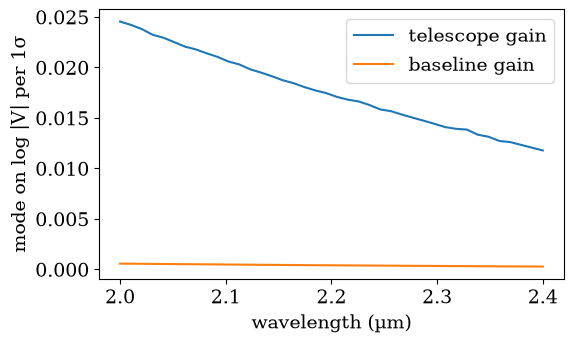

In [5]:
template = build_template(
    residuals, "tutorial", {"resolution": "MEDIUM"}, k_vis2=1, k_t3phi=0, folds=4
)
template_path = template.save(work / "tutorial_template.npz")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(template.wave * 1e6, template.vis2_tel[0], label="telescope gain")
ax.plot(template.wave * 1e6, template.vis2_base[0], label="baseline gain")
ax.set(xlabel="wavelength (µm)", ylabel="mode on log |V| per 1σ")
ax.legend()
plt.show()

## 3. Calibrating the science with the template

`virgil-vlti-calibrate --template` writes the template's modes beside each calibrated file, as `<file>.template_modes.npz`, laid out like the file's tables.

One choice matters here. By default the calibration adds a leave-one-out transfer-function error, which carries this same systematic, but as if it were **independent from channel to channel**. With a template the modes carry the systematic instead, so we keep only the statistical part of the transfer function's error (`--tf-error propagated`); otherwise it would be counted twice.

In [6]:
out = work / "calibrated"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    calibrate(
        [str(raw), "--out", str(out), "--template", str(template_path), "--tf-error", "propagated"]
    )
files = sorted(out.glob("*/*.fits"))
modes_file = files[0].with_suffix(".template_modes.npz").name
print(len(files), "calibrated science files, each with", modes_file)

2024-03-31T02:45:36  4 CAL  -> 2024-03-30/target_20240331T024536.fits  (good V2 1.00)


2024-03-31T03:28:48  4 CAL  -> 2024-03-30/target_20240331T032848.fits  (good V2 1.00)


2024-03-31T04:12:00  4 CAL  -> 2024-03-30/target_20240331T041200.fits  (good V2 1.00)


2024-04-01T02:45:36  4 CAL  -> 2024-03-31/target_20240401T024536.fits  (good V2 1.00)


2024-04-01T03:28:48  4 CAL  -> 2024-03-31/target_20240401T032848.fits  (good V2 1.00)


...

2024-04-06T04:12:00  4 CAL  -> 2024-04-05/target_20240406T041200.fits  (good V2 1.00)


2024-04-07T02:45:36  4 CAL  -> 2024-04-06/target_20240407T024536.fits  (good V2 1.00)


2024-04-07T03:28:48  4 CAL  -> 2024-04-06/target_20240407T032848.fits  (good V2 1.00)


2024-04-07T04:12:00  4 CAL  -> 2024-04-06/target_20240407T041200.fits  (good V2 1.00)


24 calibrated science files, each with target_20240331T024536.template_modes.npz


virgil never imports virgil-vlti, so the hand-off is arrays: `virgil_vlti.to_oidata` reads the calibrated files (any number of them), applies virgil's own window and observable selection, and attaches `with_gains(modes=...)` and `with_closure_offsets(modes=...)` from the `.template_modes.npz` (and the calibrators' `.modes.npz`) beside each file. The modes are lined up sample for sample with the selected data, zero on flagged samples, and modes with the same name in different files are one parameter. For data without a template's mode files, `template=` lays a template (for PIONIER, one from the pair test) on each file instead.

In [7]:
from virgil_vlti import to_oidata

## 4. Fitting in virgil, with and without the modes

We fit the disk's size to each science file twice: with the calibrated (diagonal) errors, and with the template's modes as gains, which virgil marginalises analytically. With 24 files we can check whose error bars are right: the **pulls**, (fit − truth)/σ, should scatter with unit standard deviation.

In [8]:
import numpyro.distributions as dist
from virgil.fitting import fit
from virgil.inference import laplace_cov
from virgil.models import GaussianDisk
from virgil.oidata import OIData
from virgil.oifits import read_oifits

TRUE_SIGMA = FWHM / (2 * np.sqrt(2 * np.log(2)))
start = GaussianDisk(sigma=2.0)
priors = {"sigma": dist.Uniform(0.1, 5.0)}

results = {"diagonal errors": [], "template modes": []}
for path in files:
    plain = OIData(read_oifits(str(path), insname=INS))
    modelled = to_oidata(path, INS)
    runs = (("diagonal errors", plain), ("template modes", modelled))
    for label, data in runs:
        result = fit(start, priors, data)
        sigma = float(result.values["sigma"])
        error = float(np.sqrt(laplace_cov([sigma], ["sigma"], data, result.model)[0, 0]))
        chi2 = sum(result.info["chi2"]) / sum(result.info["ndata"])
        results[label].append((sigma, error, chi2))

print(f"{'':<16}{'rms pull':>10}{'median σ (mas)':>16}{'scatter (mas)':>15}{'median χ²/N':>13}")
for label, rows in results.items():
    sigma, error, chi2 = np.array(rows).T
    pull = (sigma - TRUE_SIGMA) / error
    print(
        f"{label:<16}{np.sqrt(np.mean(pull**2)):>10.2f}{np.median(error):>16.4f}"
        f"{np.std(sigma):>15.4f}{np.median(chi2):>13.2f}"
    )

                  rms pull  median σ (mas)  scatter (mas)  median χ²/N
diagonal errors      30.46          0.0003         0.0099         3.23
template modes        1.23          0.0017         0.0021         1.01


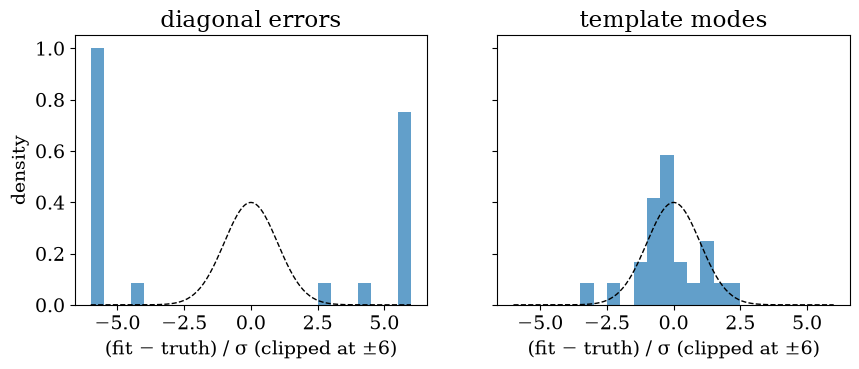

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
bins = np.linspace(-6, 6, 25)
x = np.linspace(-6, 6, 200)
for ax, (label, rows) in zip(axes, results.items(), strict=True):
    sigma, error, _ = np.array(rows).T
    pull = np.clip((sigma - TRUE_SIGMA) / error, -6, 6)
    ax.hist(pull, bins, density=True, alpha=0.7)
    ax.plot(x, np.exp(-(x**2) / 2) / np.sqrt(2 * np.pi), "k--", lw=1)
    ax.set(title=label, xlabel="(fit − truth) / σ (clipped at ±6)")
axes[0].set_ylabel("density")
plt.show()

With diagonal errors, the gains shared by a frame's 40 channels look like signal: the disk's size is quoted to a precision the data don't have, and the pulls spread far beyond ±1. With the template's modes marginalised, the error bars grow to what the systematic allows and the pulls are close to unit Gaussians (rms 1.2 over 24 files; fitting the modes' width, `vis_gain_modes`, gives 0.96).

The modes matter here because the grey part of the systematic looks like a change of size. A purely chromatic systematic, with no grey part, barely biases the size, and diagonal errors then give pulls near 1 too: whether a systematic hurts depends on the model being fitted.

## On real data

One template ships with the package (`virgil_vlti.templates.shipped()` lists them; `Template.load(name)` loads one), from a pilot PCA of archival GRAVITY calibrators:

| Template | Configuration | V² components | Closure-phase components |
|---|---|---|---|
| `gravity_single_medium_combined_2023-2025` | single field, MEDIUM, combined polarisation, 2.00–2.45 µm | 4: 1.9%, 0.52%, 0.43%, 0.29% per channel in V², 41–81% telescope-based | 2: 0.33°, 0.25° |

* Build templates from archival calibrators of the same instrument mode with `virgil-vlti-calpca` (residuals and cross-validation) and `virgil-vlti-template` (the modes); see the [command-line tools](command_line.md) and the [calibrator PCA design note](design/gravity_calibrator_pca.md) for the GRAVITY pilot.
* Calibrate with `--tf-error propagated` when you use a template, so that the systematic isn't counted twice.
* A template describes one configuration (field, resolution, polarisation, and optionally telescopes): `template_modes` refuses data in another one (`strict=False` only warns) and gives no modes outside the template's wavelength range. In dual field, the science fibre's offset from the fringe tracker decides the field (`virgil_vlti.gravity.field_mode`): `DUAL_ON` on the fringe-tracking star, `DUAL_OFF` on another star in the field, `DUAL_WIDE` beyond 4″.
* Closure-phase components (`k_t3phi`) become modes for `OIData.with_closure_offsets(modes=...)`, in radians (the template stores degrees). Keep only the closure phases virgil keeps (unflagged and finite).
* To let the data set the template's overall width, fit the noise term `vis_gain_modes`, with a log-uniform prior around 1.